# Transfer learning with a pretrained ResNet-18
A ResNet-18 trained on ImageNet, adapted to our 5 styles.

1. **Step A**: freeze the backbone, train only the new head.
2. **Step B**: unfreeze the last block `layer4` and fine-tune it with the head.
3. **Step C**: train longer with regularisation (data augmentation, dropout, weight decay, cosine learning rate); the better of B and C on validation is kept.
4. **Errors**: confusion matrix and wrong paintings.
5. **Comparison** with the MLP: accuracy, size, CPU time (the director's question).
6. **Idea from NVIDIA VSS**: a confidence guardrail and "similar artworks" search with the ResNet features.

**On Colab only** (GPU: *Runtime → Change runtime type → T4 GPU*): uncomment and run the cell below first. It mounts Google Drive, clones the repo and copies the images into `data/`. Change `DATA_ON_DRIVE` to where the `wikiart_style5` folder is on your Drive. Locally (VS Code / Jupyter with `.venv`), skip it.

In [ ]:
#  --- Colab only ---
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_ON_DRIVE = "/content/drive/MyDrive/wikiart_style5"     # <- adapt
# !git clone -q https://github.com/raniamehria/museum-guide.git /content/museum-guide   # main: data.py + split.csv
# %cd /content/museum-guide
# !rm -rf data/wikiart_style5 && mkdir -p data && cp -r "{DATA_ON_DRIVE}" data/wikiart_style5   # fresh copy: running it twice must not nest the folder
# !find data/wikiart_style5 -name "*.jpg" | wc -l                                             # must print 1500
# !ls data/wikiart_style5 | head

## Setup
Imports, fixed random seeds (same result every run) and the settings: 5 epochs per step, 5 styles.

In [2]:
import os
import sys
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")                  # run from the repo root, where data/ and splits/ are
sys.path.insert(0, "src")           # find the museum_guide package (src/museum_guide), no install needed

import copy
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score
from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights

from museum_guide.data import get_dataloaders, load_images

np.random.seed(0)
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS_HEAD = 5
EPOCHS_FT = 5
N_CLASSES = 5
CLASSES = ["Baroque", "Cubism", "Impressionism", "Pop_Art", "Ukiyo_e"]
print("device:", device)

device: cuda


## Data
The shared split (1 000 train / 250 validation / 250 test, grouped by artist). Images are normalised with the ImageNet mean and std, because the pretrained network expects inputs prepared like the photos it was trained on.

In [3]:
train_loader, val_loader, test_loader = get_dataloaders("resnet", batch_size=64)
train_eval_loader = DataLoader(train_loader.dataset, batch_size=250)     # train set measured without shuffling
loss_fn = nn.CrossEntropyLoss()
xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape))

split          test  train  val
label                          
Baroque          52    197   51
Cubism           53    204   43
Impressionism    57    188   55
Pop_Art          52    191   57
Ukiyo_e          36    220   44
Split validated!
one batch: (64, 3, 128, 128) (64,)


## Helper functions
Evaluation, the training loop (keeps the best validation epoch), learning curves, macro-F1 and the CPU time for one image.

In [4]:
# Loss and accuracy of a model on one data loader
def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


# One training epoch; model.eval() keeps the BatchNorm statistics learned on ImageNet
def train_transfer_epoch(model, loader, loss_fn, optimizer):
    model.eval()                                   # batch norm keeps its ImageNet statistics
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()


# Training loop that records loss and accuracy at every epoch
def new_history():
    return {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}


def record(history, model, optimizer):
    """Measure the model on the training and validation sets and append the results to the history."""
    tl, ta = evaluate(model, train_eval_loader, loss_fn)
    vl, va = evaluate(model, val_loader, loss_fn)
    history["train_loss"].append(tl); history["train_acc"].append(ta)
    history["val_loss"].append(vl); history["val_acc"].append(va)
    history["lr"].append(optimizer.param_groups[0]["lr"])


def fit(model, optimizer, n_epochs, train_epoch_fn=train_transfer_epoch, scheduler=None, verbose=False, seed=1):
    torch.manual_seed(seed)                    # same order of the mini-batches for every run with the same seed
    history = new_history()
    best_acc, best_state, best_epoch = -1.0, None, 0
    for epoch in range(n_epochs):
        train_epoch_fn(model, train_loader, loss_fn, optimizer)
        record(history, model, optimizer)
        if scheduler is not None:
            scheduler.step()
        if history["val_acc"][-1] > best_acc:  # early stopping: remember the best validation epoch
            best_acc, best_epoch = history["val_acc"][-1], epoch + 1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"epoch {epoch + 1:2d}  train loss {history['train_loss'][-1]:.3f}  "
                  f"val loss {history['val_loss'][-1]:.3f}  val acc {history['val_acc'][-1]:.3f}")
    model.load_state_dict(best_state)          # keep the best epoch, not the last one
    print(f"kept epoch {best_epoch} (best val acc {best_acc:.3f})")
    return history


def plot_history(history, title=""):
    e = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(e, history["train_loss"], label="train"); axes[0].plot(e, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
    axes[1].plot(e, history["train_acc"], label="train"); axes[1].plot(e, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title)
    plt.show()


# Extra measures for the director's question: macro-F1 and CPU time per image
def macro_f1(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(model(xb.to(device)).argmax(dim=1).cpu())
            labels.append(yb)
    return f1_score(torch.cat(labels), torch.cat(preds), average="macro")


def cpu_latency_ms(model, n=50, shape=(1, 3, 128, 128), threads=1):
    """Milliseconds to classify ONE image on the CPU. threads=1: one core, like a modest kiosk CPU."""
    model = model.cpu().eval()
    x = torch.randn(*shape)                        # one visitor = one image (batch 1)
    old_threads = torch.get_num_threads()
    torch.set_num_threads(threads)
    with torch.no_grad():
        for _ in range(5):                         # warm-up, not timed
            model(x)
        t0 = time.perf_counter()
        for _ in range(n):
            model(x)
    torch.set_num_threads(old_threads)             # give the other cells all the cores back
    return (time.perf_counter() - t0) / n * 1000


def file_size_mb(model, path):
    """Size of the saved weights: what the kiosk has to store."""
    torch.save(model.state_dict(), path)
    return os.path.getsize(path) / 1e6

## Step A: a new head on a frozen backbone
Load ResNet-18 pretrained on ImageNet and replace its last layer (1000 ImageNet classes) by a new layer for our 5 styles.

In [5]:
torch.manual_seed(0)
model_tl = resnet18(weights=ResNet18_Weights.DEFAULT)
print("original head:", model_tl.fc)
model_tl.fc = nn.Linear(512, N_CLASSES)
model_tl = model_tl.to(device)
print("new head:", model_tl.fc, "| parameters:", count_parameters(model_tl))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 76.1MB/s]


original head: Linear(in_features=512, out_features=1000, bias=True)
new head: Linear(in_features=512, out_features=5, bias=True) | parameters: 11179077


Freeze every layer except the new head: only 512 × 5 + 5 = 2 565 parameters are trained.

In [6]:
for p in model_tl.parameters():
    p.requires_grad = False
for p in model_tl.fc.parameters():
    p.requires_grad = True
n_trainable = count_parameters(model_tl, trainable_only=True)
print("Trainable:", n_trainable, "of", count_parameters(model_tl))          # 512 x 5 + 5 = 2565

Trainable: 2565 of 11179077


Train the head only (Adam, learning rate 3e-3), then measure test accuracy and macro-F1.

epoch  1  train loss 0.785  val loss 0.896  val acc 0.628
epoch  2  train loss 0.586  val loss 0.781  val acc 0.708
epoch  3  train loss 0.487  val loss 0.700  val acc 0.724
epoch  4  train loss 0.467  val loss 0.780  val acc 0.708
epoch  5  train loss 0.393  val loss 0.733  val acc 0.740
kept epoch 5 (best val acc 0.740)


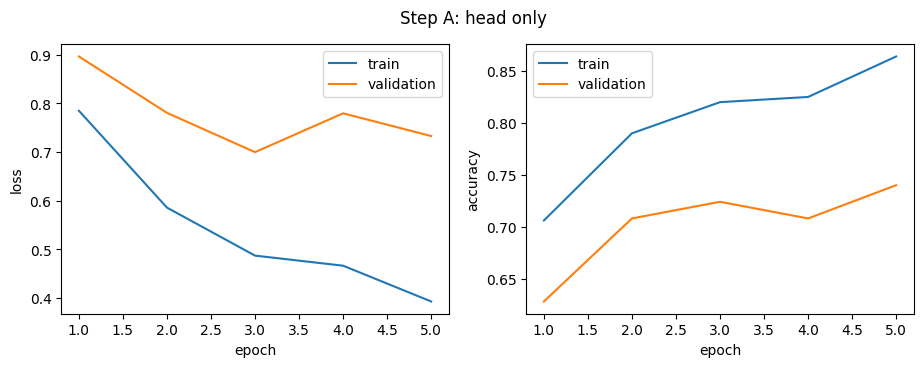

Head only: test accuracy 0.732, macro-F1 0.734 (8 s). Chance level is 0.20.


In [7]:
t0 = time.time()
optimizer = torch.optim.Adam(model_tl.fc.parameters(), lr=3e-3)
history_head = fit(model_tl, optimizer, EPOCHS_HEAD, verbose=True)
acc_head = evaluate(model_tl, test_loader, loss_fn)[1]
f1_head = macro_f1(model_tl, test_loader)
time_head = time.time() - t0
plot_history(history_head, "Step A: head only")
print(f"Head only: test accuracy {acc_head:.3f}, macro-F1 {f1_head:.3f} ({time_head:.0f} s). Chance level is 0.20.")

## Step B: fine-tune the last block
Unfreeze `layer4`, the most ImageNet-specific block, and train it with a 10x smaller learning rate than the head, to adjust the pretrained weights without destroying them.

Trainable: 8396293 of 11179077
epoch  1  train loss 0.253  val loss 0.692  val acc 0.768
epoch  2  train loss 0.047  val loss 0.786  val acc 0.752
epoch  3  train loss 0.030  val loss 0.914  val acc 0.748
epoch  4  train loss 0.013  val loss 0.756  val acc 0.784
epoch  5  train loss 0.013  val loss 0.867  val acc 0.752
kept epoch 4 (best val acc 0.784)


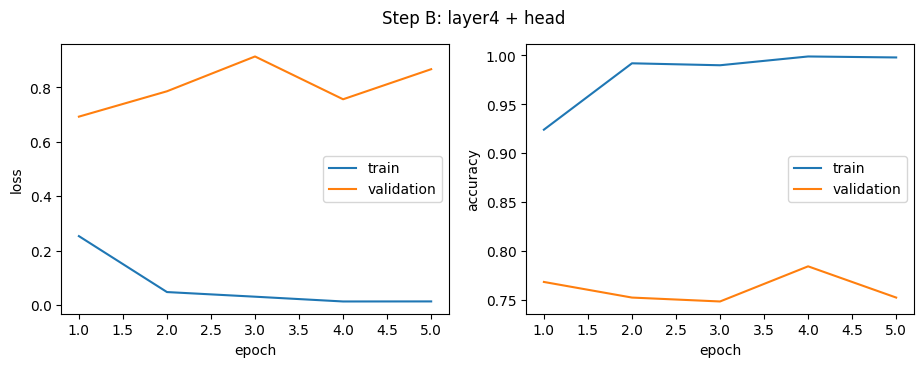

Fine-tuned: test accuracy 0.780, macro-F1 0.780 (head only 0.732) in 6 s.


In [8]:
t0 = time.time()
for p in model_tl.layer4.parameters():
    p.requires_grad = True
print("Trainable:", count_parameters(model_tl, trainable_only=True), "of", count_parameters(model_tl))
optimizer = torch.optim.Adam([{"params": model_tl.layer4.parameters(), "lr": 1e-4},
                              {"params": model_tl.fc.parameters(), "lr": 1e-3}])
history_ft = fit(model_tl, optimizer, EPOCHS_FT, verbose=True)
acc_ft = evaluate(model_tl, test_loader, loss_fn)[1]
f1_ft = macro_f1(model_tl, test_loader)
time_ft = time.time() - t0
plot_history(history_ft, "Step B: layer4 + head")
print(f"Fine-tuned: test accuracy {acc_ft:.3f}, macro-F1 {f1_ft:.3f} (head only {acc_head:.3f}) in {time_ft:.0f} s.")

## Step C: train longer with regularisation
Step B overfits: the train loss goes to almost 0 while the validation loss rises. Here we train 3 times longer (3 + 15 epochs) but add four simple regularisers:
- **data augmentation**: a random left-right flip and a random crop (the painting moves by up to 12 px). Every epoch sees slightly different images, so the network cannot memorise the pixels. No colour changes: colour is part of the style.
- **dropout 0.5** before the new head: during training, half of the 512 features are switched off at random, so the head cannot rely on a few of them.
- **weight decay** (AdamW, 1e-2): at every step the weights shrink a little, which keeps them small.
- **cosine learning rate**: starts at the step B rates and slowly goes down to 0, so the last epochs only make small adjustments.

Early stopping still keeps the best validation epoch. Use a GPU on Colab: about 2 minutes (much longer on a CPU).

epoch  1  train loss 0.884  val loss 1.000  val acc 0.608
epoch  2  train loss 0.669  val loss 0.801  val acc 0.684
epoch  3  train loss 0.591  val loss 0.720  val acc 0.716
kept epoch 3 (best val acc 0.716)
epoch  1  train loss 0.537  val loss 0.738  val acc 0.720
epoch  2  train loss 0.337  val loss 0.607  val acc 0.784
epoch  3  train loss 0.253  val loss 0.567  val acc 0.760
epoch  4  train loss 0.233  val loss 0.605  val acc 0.744
epoch  5  train loss 0.154  val loss 0.669  val acc 0.752
epoch  6  train loss 0.102  val loss 0.628  val acc 0.776
epoch  7  train loss 0.078  val loss 0.584  val acc 0.784
epoch  8  train loss 0.069  val loss 0.623  val acc 0.780
epoch  9  train loss 0.048  val loss 0.624  val acc 0.788
epoch 10  train loss 0.040  val loss 0.715  val acc 0.764
epoch 11  train loss 0.035  val loss 0.650  val acc 0.784
epoch 12  train loss 0.029  val loss 0.686  val acc 0.772
epoch 13  train loss 0.027  val loss 0.667  val acc 0.772
epoch 14  train loss 0.026  val loss 0

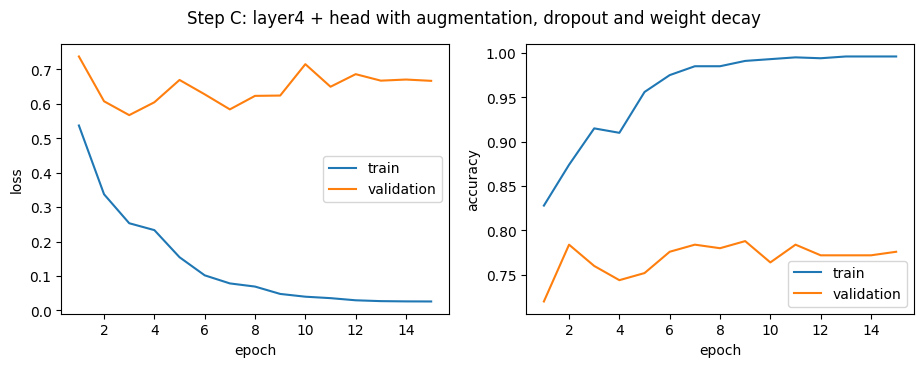

Regularised: test accuracy 0.776, macro-F1 0.782 (step B 0.780) in 20 s.


In [9]:
EPOCHS_C_HEAD = 3      # head only, as in step A
EPOCHS_C = 15          # layer4 + head: 3x more epochs than step B, made safe by regularisation + early stopping
DROPOUT = 0.5
WEIGHT_DECAY = 1e-2    # AdamW: the weights shrink a little at every step (L2 regularisation)
SHIFT = 12             # random crop: the painting can move by up to 12 px


def augment(xb):
    """Random left-right flip (per image) + random crop (same shift for the whole batch)."""
    flip = torch.rand(len(xb), device=xb.device) < 0.5
    xb = torch.where(flip.view(-1, 1, 1, 1), xb.flip(-1), xb)
    size = xb.shape[-1]
    xb = F.pad(xb, (SHIFT, SHIFT, SHIFT, SHIFT), mode="reflect")   # mirror the borders instead of adding black bands
    i, j = torch.randint(0, 2 * SHIFT + 1, (2,)).tolist()
    return xb[..., i:i + size, j:j + size]


def train_regularised_epoch(model, loader, loss_fn, optimizer):
    model.eval()           # BatchNorm keeps its ImageNet statistics (as in steps A and B)...
    model.fc.train()       # ...but dropout must be ON during training, and it lives in fc
    for xb, yb in loader:
        xb, yb = augment(xb.to(device)), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()


def train_step_c(seed=0, verbose=True):
    """Step C from scratch for one random seed (seed: initialisation of the head, batch order, augmentation, dropout)."""
    torch.manual_seed(seed)
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(512, N_CLASSES))   # dropout just before the new head
    model = model.to(device)

    # C1: head only (a new layer can learn fast: learning rate 3e-3, as in step A)
    optimizer = torch.optim.AdamW(model.fc.parameters(), lr=3e-3, weight_decay=WEIGHT_DECAY)
    fit(model, optimizer, EPOCHS_C_HEAD, train_epoch_fn=train_regularised_epoch, verbose=verbose, seed=seed + 1)

    # C2: unfreeze layer4, same learning rates as step B, cosine schedule over the 15 epochs
    for p in model.layer4.parameters():
        p.requires_grad = True
    optimizer = torch.optim.AdamW([{"params": model.layer4.parameters(), "lr": 1e-4},
                                   {"params": model.fc.parameters(), "lr": 1e-3}], weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_C)
    history = fit(model, optimizer, EPOCHS_C, train_epoch_fn=train_regularised_epoch, scheduler=scheduler,
                  verbose=verbose, seed=seed + 1)
    return model, history


t0 = time.time()
model_c, history_c = train_step_c(seed=0)

n_trainable_c = count_parameters(model_c, trainable_only=True)
acc_c = evaluate(model_c, test_loader, loss_fn)[1]
f1_c = macro_f1(model_c, test_loader)
time_c = time.time() - t0
plot_history(history_c, "Step C: layer4 + head with augmentation, dropout and weight decay")
print(f"Regularised: test accuracy {acc_c:.3f}, macro-F1 {f1_c:.3f} (step B {acc_ft:.3f}) in {time_c:.0f} s.")

### Is the difference real? Three random seeds
One run can be lucky: the random seed decides the initial weights of the new head, the order of the mini-batches, the augmentation and the dropout. We retrain steps B and C with seeds 1 and 2 (seed 0 is the run above) and report the **mean ± standard deviation**. If the gap between B and C is smaller than the spread between seeds, it is luck, not a real improvement. About 5 minutes on a Colab GPU.

In [10]:
SEEDS = [0, 1, 2]


def train_step_b(seed):
    """Steps A then B from scratch for one seed (seed 0 gives back the run above)."""
    torch.manual_seed(seed)
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Linear(512, N_CLASSES)
    model = model.to(device)
    fit(model, torch.optim.Adam(model.fc.parameters(), lr=3e-3), EPOCHS_HEAD, seed=seed + 1)
    for p in model.layer4.parameters():
        p.requires_grad = True
    optimizer = torch.optim.Adam([{"params": model.layer4.parameters(), "lr": 1e-4},
                                  {"params": model.fc.parameters(), "lr": 1e-3}])
    history = fit(model, optimizer, EPOCHS_FT, seed=seed + 1)
    return model, history


runs = []
for seed in SEEDS:
    if seed == 0:                                    # already trained above
        mb, hb, mc, hc = model_tl, history_ft, model_c, history_c
    else:
        print(f"--- seed {seed}")
        mb, hb = train_step_b(seed)
        mc, hc = train_step_c(seed, verbose=False)
    runs.append({"seed": seed,
                 "B val": max(hb["val_acc"]), "B test": evaluate(mb, test_loader, loss_fn)[1],
                 "C val": max(hc["val_acc"]), "C test": evaluate(mc, test_loader, loss_fn)[1]})
seeds_df = pd.DataFrame(runs)
seeds_df["C - B (test)"] = seeds_df["C test"] - seeds_df["B test"]
print(seeds_df.round(3).to_string(index=False))

mean_b, std_b = seeds_df["B test"].mean(), seeds_df["B test"].std()
mean_c, std_c = seeds_df["C test"].mean(), seeds_df["C test"].std()
diff = seeds_df["C - B (test)"]
print(f"\ntest accuracy over {len(SEEDS)} seeds: step B {mean_b:.3f} ± {std_b:.3f} | step C {mean_c:.3f} ± {std_c:.3f}")
print(f"C - B: {diff.mean():+.3f} on average, C better on {(diff > 0).sum()} of {len(SEEDS)} seeds")

--- seed 1
kept epoch 3 (best val acc 0.732)
kept epoch 3 (best val acc 0.808)
kept epoch 3 (best val acc 0.732)
kept epoch 14 (best val acc 0.796)
--- seed 2
kept epoch 4 (best val acc 0.744)
kept epoch 2 (best val acc 0.796)
kept epoch 3 (best val acc 0.700)
kept epoch 10 (best val acc 0.800)
 seed  B val  B test  C val  C test  C - B (test)
    0  0.784   0.780  0.788   0.776        -0.004
    1  0.808   0.788  0.796   0.796         0.008
    2  0.796   0.764  0.800   0.820         0.056

test accuracy over 3 seeds: step B 0.777 ± 0.012 | step C 0.797 ± 0.022
C - B: +0.020 on average, C better on 2 of 3 seeds


### Which model does the guide use?
We keep the better of B and C **on the validation set, averaged over the 3 seeds** (the test set only reports the result, it never chooses). The kept model is used in all the cells below. We also compare the train-validation gap at the kept epoch: a smaller gap means less overfitting.

In [11]:
def gap_at_best(history):
    """Train accuracy minus validation accuracy at the epoch kept by early stopping."""
    k = history["val_acc"].index(max(history["val_acc"]))
    return history["train_acc"][k] - history["val_acc"][k]


best_val_b, best_val_c = seeds_df["B val"].mean(), seeds_df["C val"].mean()   # mean over the seeds
gap_b, gap_c = gap_at_best(history_ft), gap_at_best(history_c)
n_trainable_ft = count_parameters(model_tl, trainable_only=True)    # step B, before model_tl may be replaced
model_b = model_tl
if best_val_c > best_val_b:
    model_tl = model_c
final_step = "C" if model_tl is model_c else "B"
print(f"mean best val acc over {len(SEEDS)} seeds: step B {best_val_b:.3f}, step C {best_val_c:.3f} -> the guide uses step {final_step} (seed 0)")
print(f"train-validation accuracy gap at the kept epoch: step B {gap_b:.2f}, step C {gap_c:.2f}")

mean best val acc over 3 seeds: step B 0.796, step C 0.795 -> the guide uses step B (seed 0)
train-validation accuracy gap at the kept epoch: step B 0.21, step C 0.20


Save the weights (outside Git) and measure the cost on a kiosk: CPU time per image and file size.

In [12]:
os.makedirs("models", exist_ok=True)                            # weights stay outside Git (.gitignore)
size_mb = file_size_mb(model_tl, "models/resnet18.pt")
lat_resnet = cpu_latency_ms(model_tl)                                       # 1 core: a modest kiosk CPU
lat_resnet_all = cpu_latency_ms(model_tl, threads=torch.get_num_threads())  # all the cores of this computer
print(f"CPU time per image: {lat_resnet:.1f} ms on 1 core, {lat_resnet_all:.1f} ms on {torch.get_num_threads()} cores")
print(f"size: {size_mb:.1f} MB | parameters: {count_parameters(model_tl):,}")
model_tl = model_tl.to(device)
!cp models/resnet18.pt "/content/drive/MyDrive/resnet18.pt"   # Colab only: keep the weights for qa_hybrid.ipynb


CPU time per image: 23.0 ms on 1 core, 22.5 ms on 1 cores
size: 44.8 MB | parameters: 11,179,077


### Steps A and B together
The dashed line is where `layer4` is unfrozen. If the train loss keeps falling while the validation loss rises, the model is **overfitting** (8.4 million trainable parameters for 1 000 paintings); `fit` keeps the best validation epoch (early stopping).

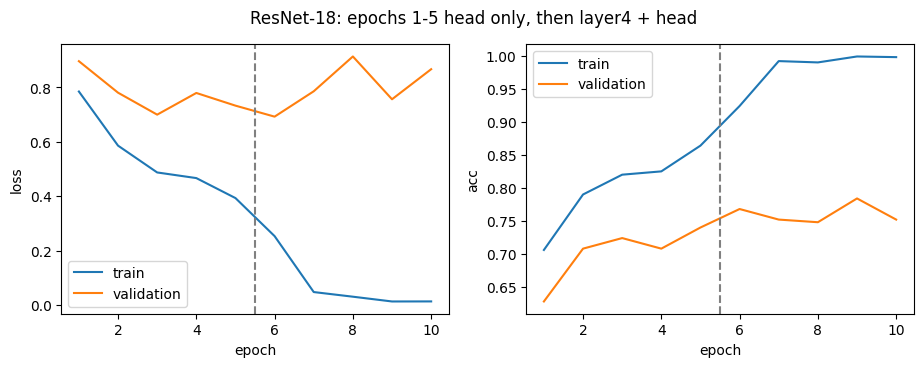

In [13]:
history = {k: history_head[k] + history_ft[k] for k in history_head}
e = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, key in zip(axes, ["loss", "acc"]):
    ax.plot(e, history[f"train_{key}"], label="train")
    ax.plot(e, history[f"val_{key}"], label="validation")
    ax.axvline(EPOCHS_HEAD + 0.5, color="grey", linestyle="--")
    ax.set_xlabel("epoch"); ax.set_ylabel(key); ax.legend()
fig.suptitle(f"ResNet-18: epochs 1-{EPOCHS_HEAD} head only, then layer4 + head")
plt.show()

## Errors of the fine-tuned model
Same analysis as `mlp.ipynb`: confusion matrix and the paintings it gets wrong.

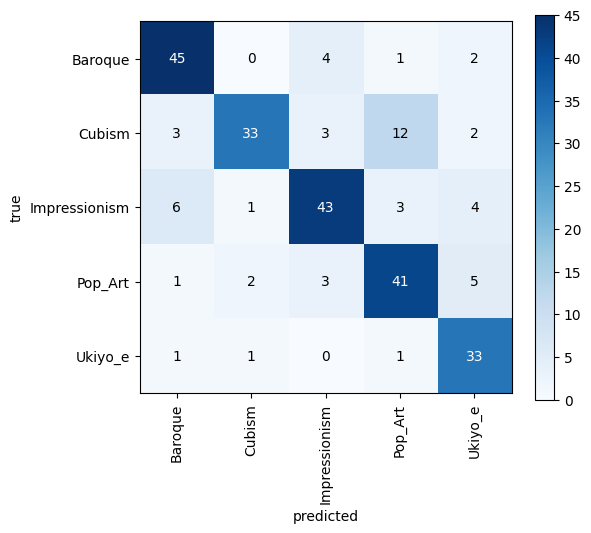

Baroque        accuracy 0.87
Cubism         accuracy 0.62
Impressionism  accuracy 0.75
Pop_Art        accuracy 0.79
Ukiyo_e        accuracy 0.92
most frequent mistake: Cubism predicted as Pop_Art (12 times)


In [14]:
model_tl.eval()
preds, labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds.append(model_tl(xb.to(device)).argmax(dim=1).cpu())
        labels.append(yb)
preds, labels = torch.cat(preds), torch.cat(labels)

cm = confusion_matrix(labels, preds, labels=range(N_CLASSES))
off = cm.copy()
np.fill_diagonal(off, 0)
true_cls, pred_cls = np.unravel_index(off.argmax(), off.shape)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(N_CLASSES), CLASSES, rotation=90); plt.yticks(range(N_CLASSES), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()
for i, c in enumerate(CLASSES):
    print(f"{c:14s} accuracy {cm[i, i] / cm[i].sum():.2f}")
print(f"most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times)")

The paintings the model gets wrong (title: true style / predicted style).

55 mistakes out of 250 (title: true / predicted)


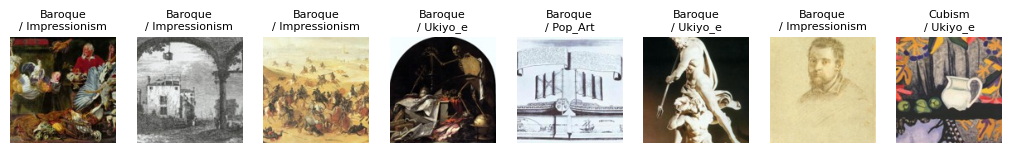

In [15]:
X, y, meta = load_images()                                         # images in [0, 1], to look at them
split = pd.read_csv("splits/split.csv")
X_test_raw = X[torch.tensor((split["split"] == "test").values)]
X_train_raw = X[torch.tensor((split["split"] == "train").values)]


def show_images(images, titles, n=8):
    n = min(n, len(images))
    if n == 0:
        return
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.0), squeeze=False)
    for ax, img, title in zip(axes[0], images[:n], titles[:n]):
        ax.imshow(img.permute(1, 2, 0))                             # (3, H, W) -> (H, W, 3)
        ax.set_title(title, fontsize=8); ax.axis("off")
    plt.show()


wrong = (preds != labels).nonzero(as_tuple=True)[0]
print(len(wrong), "mistakes out of", len(labels), "(title: true / predicted)")
show_images(X_test_raw[wrong], [f"{CLASSES[labels[i]]}\n/ {CLASSES[preds[i]]}" for i in wrong])

## Comparison with the MLP (the director's question)
Same split, same 250 test images. The MLP number comes from `mlp.ipynb` (Tâche 1); the classical baseline is compared in Tâche 4. With 250 test images, about ±3 points is noise.
Steps B and C have the same architecture (dropout has no weights), so they have the same CPU time and size.
The CPU time is measured here for every model with the same function (1 image, like one visitor at a kiosk); it does not depend on the trained weights, only on the architecture.

model,test accuracy,trained parameters,CPU ms / image (1 core),size MB
chance (1 / 5),0.200,0,0.00,0.00
"MLP, 3 ReLU layers",0.356,"3,187,461",0.65,12.75
"ResNet-18, head only (A)",0.732,"2,565",23.01,44.80
"ResNet-18, layer4 + head (B)",0.780,"8,396,293",23.01,44.80
"ResNet-18, regularised (C)",0.776,"8,396,293",23.01,44.80


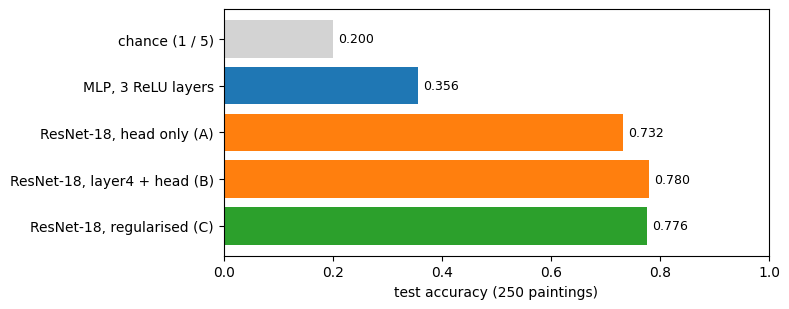

In [16]:
MLP_ACC = 0.356       # test accuracy of the tuned MLP (mlp.ipynb)

mlp = nn.Sequential(nn.Flatten(),
                    nn.Linear(3 * 64 * 64, 256),
                    nn.ReLU(),
                    nn.Linear(256, 128),
                    nn.ReLU(),
                    nn.Linear(128, 64),
                    nn.ReLU(),
                    nn.Linear(64, 5))                  # same architecture as mlp.ipynb, only to measure time and size
lat_mlp = cpu_latency_ms(mlp, shape=(1, 3, 64, 64))
size_mlp = file_size_mb(mlp, "models/mlp_untrained.pt")             # the size depends on the architecture only

results = pd.DataFrame([
    ["chance (1 / 5)", 0.20, 0, 0.0, 0.0],
    ["MLP, 3 ReLU layers", MLP_ACC, count_parameters(mlp), lat_mlp, size_mlp],
    ["ResNet-18, head only (A)", acc_head, n_trainable, lat_resnet, size_mb],
    ["ResNet-18, layer4 + head (B)", acc_ft, n_trainable_ft, lat_resnet, size_mb],
    ["ResNet-18, regularised (C)", acc_c, n_trainable_c, lat_resnet, size_mb],
], columns=["model", "test accuracy", "trained parameters", "CPU ms / image (1 core)", "size MB"])
display(results.style.format({"test accuracy": "{:.3f}", "trained parameters": "{:,}",
                              "CPU ms / image (1 core)": "{:.2f}", "size MB": "{:.2f}"})
        .hide(axis="index"))

plt.figure(figsize=(8, 3.2))
plt.barh(results["model"], results["test accuracy"], color=["lightgrey", "tab:blue", "tab:orange", "tab:orange", "tab:green"])
for i, acc in enumerate(results["test accuracy"]):
    plt.text(acc + 0.01, i, f"{acc:.3f}", va="center", fontsize=9)
plt.xlim(0, 1); plt.xlabel("test accuracy (250 paintings)"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

## Idea from NVIDIA VSS: from a classifier to a museum guide
NVIDIA **VSS** (Video Search & Summarization) works in two phases: **offline**, a vision model turns every video chunk into captions and embeddings stored in a vector database; **online**, a question is embedded, the nearest chunks are found by similarity, and **guardrails** stop wrong answers.

We borrow the idea with simple tools, one artwork = one "chunk":

| VSS | Our guide |
|---|---|
| vision model (perception) | ResNet-18 fine-tuned on our 5 styles |
| embeddings + vector DB | 512-d ResNet feature of every painting, kept in one tensor |
| similarity search | cosine similarity, top 5 |
| guardrails | if the max softmax probability < τ, say "not sure" and show the top 3 |

The heavy part (computing the features) is done **once offline**; online, the kiosk only computes one feature and one matrix product, which fits a cheap CPU.

### 1. Guardrail: answer only when the model is confident
τ is chosen on the **validation** set (never on the test set): for each τ, how many paintings the guide answers, and how often it is right when it answers.

In [17]:
def probabilities(model, loader):
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(torch.softmax(model(xb.to(device)), dim=1).cpu())
            labels.append(yb)
    return torch.cat(probs), torch.cat(labels)


val_probs, val_labels = probabilities(model_tl, val_loader)
conf, val_preds = val_probs.max(dim=1)
print("  tau  | answered | accuracy when answered")
for tau in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = conf >= tau
    acc = (val_preds[keep] == val_labels[keep]).float().mean().item() if keep.any() else float("nan")
    print(f"  {tau:.1f}  |  {keep.float().mean().item():5.0%}   |  {acc:.3f}")

  tau  | answered | accuracy when answered
  0.0  |   100%   |  0.784
  0.5  |    98%   |  0.793
  0.6  |    92%   |  0.805
  0.7  |    86%   |  0.836
  0.8  |    75%   |  0.872
  0.9  |    68%   |  0.882


What the kiosk says for one painting: the style and the story of the movement if the confidence is at least τ, otherwise "not sure" and the top 3.

In [18]:
TAU = 0.7                                      # choose it from the table above

STORIES = {                                    # what the guide tells the visitor about each movement
    "Baroque": "European art of the 17th and early 18th centuries. Strong contrasts of light and shadow, movement and emotion "
               "(Caravaggio, Rubens, Rembrandt, Velazquez).",
    "Cubism": "Started in Paris around 1907-1908 with Picasso and Braque. Objects are broken into geometric facets "
              "and shown from several viewpoints at once.",
    "Impressionism": "France, from the 1860s-1870s (Monet, Renoir, Degas). Visible brushstrokes, outdoor scenes and changing light; "
                     "the name comes from Monet's 'Impression, Sunrise'.",
    "Pop_Art": "Britain and the United States, from the late 1950s (Warhol, Lichtenstein). Images taken from advertising, "
               "comics and everyday consumer products.",
    "Ukiyo_e": "Japanese woodblock prints and paintings of the Edo period, 17th to 19th century (Hokusai, Hiroshige): "
               "'pictures of the floating world'. They inspired many Impressionists.",
}


def guide_answer(probs):
    """What the kiosk says for one painting, from its 5 softmax probabilities."""
    p, k = probs.max(dim=0)
    if p >= TAU:
        return f"{CLASSES[k]} ({p:.0%}). {STORIES[CLASSES[k]]}"
    top3 = probs.topk(3)
    return "not sure: " + ", ".join(f"{CLASSES[i]} {q:.0%}" for q, i in zip(top3.values, top3.indices))


test_probs, test_labels = probabilities(model_tl, test_loader)
for i in range(5):
    print(f"true {CLASSES[test_labels[i]]:14s} -> guide: {guide_answer(test_probs[i])}")

true Baroque        -> guide: not sure: Baroque 52%, Impressionism 48%, Cubism 0%
true Baroque        -> guide: Baroque (99%). European art of the 17th and early 18th centuries. Strong contrasts of light and shadow, movement and emotion (Caravaggio, Rubens, Rembrandt, Velazquez).
true Baroque        -> guide: not sure: Baroque 66%, Impressionism 34%, Ukiyo_e 0%
true Baroque        -> guide: Baroque (96%). European art of the 17th and early 18th centuries. Strong contrasts of light and shadow, movement and emotion (Caravaggio, Rubens, Rembrandt, Velazquez).
true Baroque        -> guide: Baroque (95%). European art of the 17th and early 18th centuries. Strong contrasts of light and shadow, movement and emotion (Caravaggio, Rubens, Rembrandt, Velazquez).


### 2. "Show me similar artworks": the ResNet as a feature extractor
Removing the head (`fc = nn.Identity()`) gives a 512-d feature per painting. We index the training paintings once (offline), then for a visitor's photo we return the 5 most similar ones by cosine similarity (online).

index: (1000, 512)


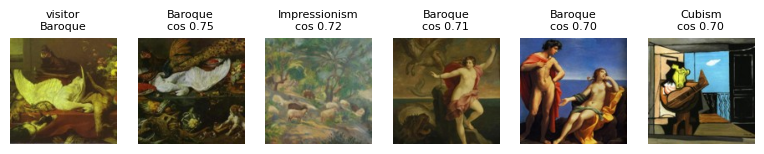

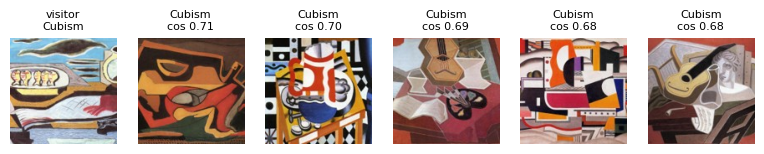

top-5 similar paintings with the same style: 71% (chance: 20%)


In [19]:
backbone = copy.deepcopy(model_tl)
backbone.fc = nn.Identity()                    # 512-d feature instead of 5 scores


def features(loader):
    backbone.eval()
    out = []
    with torch.no_grad():
        for xb, _ in loader:
            out.append(backbone(xb.to(device)).cpu())
    return F.normalize(torch.cat(out), dim=1)  # unit length: cosine = dot product


index = features(train_eval_loader)            # OFFLINE: the collection, (1000, 512)
queries = features(test_loader)                # ONLINE: the visitors' photos
print("index:", tuple(index.shape))

train_labels = train_loader.dataset.tensors[1]
for q in [0, 60]:                              # two test paintings
    scores = index @ queries[q]                # cosine similarity with all 1 000 paintings
    top = scores.topk(5).indices
    show_images(torch.cat([X_test_raw[q:q + 1], X_train_raw[top]]),
                [f"visitor\n{CLASSES[test_labels[q]]}"] + [f"{CLASSES[train_labels[i]]}\ncos {scores[i]:.2f}" for i in top],
                n=6)

# One number for the slides: how often the 5 nearest paintings have the same style as the visitor's photo
top5 = (queries @ index.T).topk(5, dim=1).indices          # (250, 5): the 5 most similar paintings of each test photo
same_style = (train_labels[top5] == test_labels.view(-1, 1)).float().mean().item()
print(f"top-5 similar paintings with the same style: {same_style:.0%} (chance: 20%)")

## Conclusion
The cell below prints the conclusion with the measured numbers (copy it to the slides).

In [20]:
best_mlp = MLP_ACC
print(f"""- Step A (head only, {n_trainable:,} trained parameters): test accuracy {acc_head:.3f}, macro-F1 {f1_head:.3f}.
  ImageNet features already separate the styles: {(acc_head - best_mlp) * 100:+.0f} points over the best MLP ({best_mlp}).
- Step B (layer4 + head, {n_trainable_ft:,} trained parameters): test accuracy {acc_ft:.3f}, macro-F1 {f1_ft:.3f}
  ({(acc_ft - acc_head) * 100:+.0f} points vs step A; about ±3 points is noise with 250 test images).
- Overfitting in step B: train loss {min(history_ft['train_loss']):.3f} vs val loss {history_ft['val_loss'][-1]:.3f} at the end -> early stopping keeps the best epoch.
- Step C (flip + crop, dropout {DROPOUT}, weight decay {WEIGHT_DECAY}, {EPOCHS_C_HEAD} + {EPOCHS_C} epochs, cosine learning rate): test accuracy {acc_c:.3f}, macro-F1 {f1_c:.3f}
  ({(acc_c - acc_ft) * 100:+.0f} points vs step B). Train-validation gap at the kept epoch: B {gap_b:.2f}, C {gap_c:.2f}.
- Over {len(SEEDS)} seeds (test accuracy): step B {mean_b:.3f} ± {std_b:.3f}, step C {mean_c:.3f} ± {std_c:.3f}; C better on {(diff > 0).sum()} of {len(SEEDS)} seeds.
- Model used by the guide (chosen on the mean validation accuracy): step {final_step}.
- Most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times). MLP: Cubism -> Impressionism (30 times).
- Cost on a kiosk CPU (1 core): ResNet {lat_resnet:.1f} ms per image and {size_mb:.0f} MB; MLP {lat_mlp:.2f} ms and {size_mlp:.1f} MB.
- VSS idea: with τ = {TAU}, the guide answers {(test_probs.max(dim=1).values >= TAU).float().mean():.0%} of the test paintings;
  the 512-d features also give "similar artworks" with one matrix product: {same_style:.0%} of the top-5 have the same style.""")

- Step A (head only, 2,565 trained parameters): test accuracy 0.732, macro-F1 0.734.
  ImageNet features already separate the styles: +38 points over the best MLP (0.356).
- Step B (layer4 + head, 8,396,293 trained parameters): test accuracy 0.780, macro-F1 0.780
  (+5 points vs step A; about ±3 points is noise with 250 test images).
- Overfitting in step B: train loss 0.013 vs val loss 0.867 at the end -> early stopping keeps the best epoch.
- Step C (flip + crop, dropout 0.5, weight decay 0.01, 3 + 15 epochs, cosine learning rate): test accuracy 0.776, macro-F1 0.782
  (-0 points vs step B). Train-validation gap at the kept epoch: B 0.21, C 0.20.
- Over 3 seeds (test accuracy): step B 0.777 ± 0.012, step C 0.797 ± 0.022; C better on 2 of 3 seeds.
- Model used by the guide (chosen on the mean validation accuracy): step B.
- Most frequent mistake: Cubism predicted as Pop_Art (12 times). MLP: Cubism -> Impressionism (30 times).
- Cost on a kiosk CPU (1 core): ResNet 23.0 ms per image an